# GCI Global 2026 — Home Credit Default Risk

**A leakage-safe, end-to-end solution**

This notebook predicts the probability that a customer will experience payment difficulties (`TARGET = 1`). The competition metric is **ROC AUC**.

## Executive summary

| Item | Value |
|---|---|
| Training customers | 171,202 |
| Test customers | 61,500 |
| Original predictors | 32 |
| Engineered predictors | 84 |
| Metric | ROC AUC |
| Validation | 5-fold stratified outer CV + inner early-stopping split |
| Models | CatBoost, LightGBM, XGBoost |
| Ensemble | Nested weight selection and logistic stacking |
| Final output | `submission.csv` with 61,500 probabilities |

### What changed relative to the original notebook

1. **No early-stopping leakage.** Each outer fold uses a separate inner validation split for early stopping. The outer validation fold is never used to choose the number of trees.
2. **Stronger feature engineering.** The model uses 84 features built only from `train.csv` and `test.csv`, including financial ratios, time ratios, `EXT_SOURCE` aggregates, missing-value indicators, and bureau-request summaries.
3. **Honest ensemble evaluation.** Ensemble weights are selected on the other outer folds and evaluated on the held-out fold. This avoids the optimistic comparison produced when weights are tuned and scored on the same OOF predictions.
4. **Uncertainty and paired comparisons.** Every key result includes fold-level standard deviations and bootstrap confidence intervals. The best blend is compared with CatBoost using a paired bootstrap.
5. **A real submission.** The notebook writes `submission.csv` from full-data models, not from a placeholder.

> **Reference baseline (original notebook):** CatBoost with 32 raw features reached an OOF AUC of **0.754016**, but its early stopping used the same validation fold that produced the OOF score. The numbers in this notebook are therefore produced under a stricter protocol and are not a like-for-like ablation; they are a safer estimate of out-of-sample performance.


## 1. Setup and data

The notebook uses only the two files allowed by the competition: `train.csv` and `test.csv`. All preprocessing is fitted on the training data or is row-wise, so no target information leaks into the features.


In [1]:
%matplotlib inline
import json
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm as lgb
from lightgbm import LGBMClassifier, early_stopping
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from scipy.stats import rankdata, ttest_rel

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5
START_TIME = time.time()

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("LightGBM:", lgb.__version__)
print("CatBoost:", __import__("catboost").__version__)
print("XGBoost:", __import__("xgboost").__version__)


Python: 3.14.6
pandas: 3.0.3
numpy: 2.5.0
scikit-learn: 1.9.1
LightGBM: 4.7.0
CatBoost: 1.2.10
XGBoost: 3.4.1


In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
print("Positive rate: {:.2%}".format(train["TARGET"].mean()))
print("Train IDs unique:", train["SK_ID_CURR"].is_unique)
print("Test IDs unique: ", test["SK_ID_CURR"].is_unique)
print("ID overlap:      ", len(set(train["SK_ID_CURR"]) & set(test["SK_ID_CURR"])))

display(train.head())
display(train.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("count"))


Train shape: (171202, 34)
Test shape:  (61500, 33)
Positive rate: 8.07%
Train IDs unique: True
Test IDs unique:  True
ID overlap:       0


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,0.010032,-9233,-878,-333.0,-522,NaN,1,1,1,Core staff,2.0,2,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,0.008019,-20148,365243,-4469.0,-3436,NaN,1,0,0,Other,2.0,2,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,0.004960,-18496,-523,-3640.0,-2050,NaN,1,1,1,Core staff,2.0,2,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,0.005002,-24177,365243,-4950.0,-3951,NaN,1,0,0,Other,1.0,3,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,0.006296,-10685,-697,-5101.0,-3226,NaN,1,1,1,Drivers,2.0,3,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


,count
dtype,
float64,16
int64,10
str,8


## 2. Exploratory data analysis

The goal of this section is to identify the main data-quality issues and the strongest univariate signals before modeling. The analysis is descriptive; it does not use the test target, which is unavailable.


No default (0): 157,381 (91.93%)
Default    (1): 13,821 (8.07%)


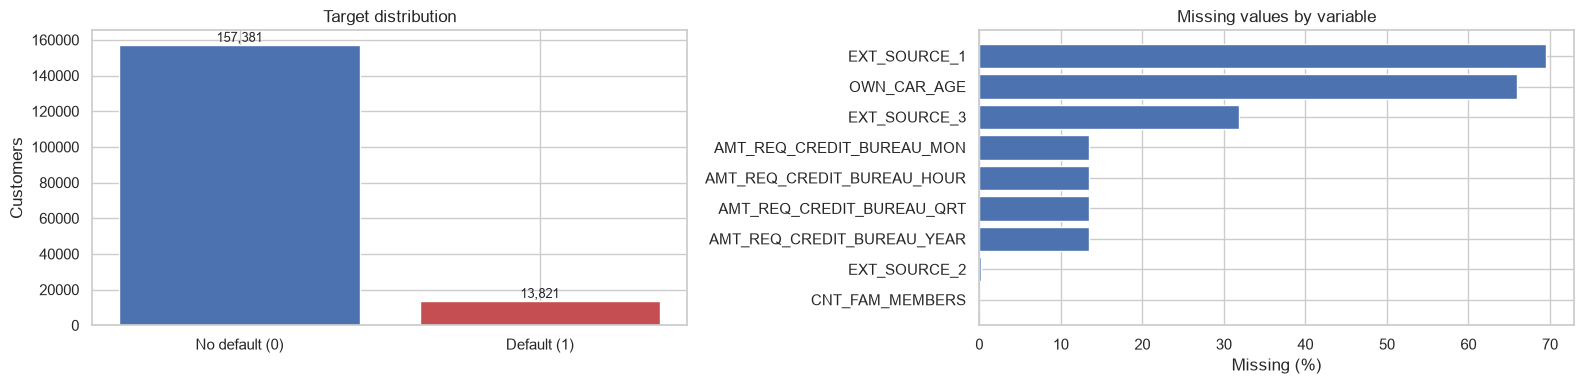

,Missing,Percentage
EXT_SOURCE_1,118928,69.47
OWN_CAR_AGE,112992,66.00
EXT_SOURCE_3,54586,31.88
AMT_REQ_CREDIT_BUREAU_MON,23116,13.50
AMT_REQ_CREDIT_BUREAU_HOUR,23116,13.50
AMT_REQ_CREDIT_BUREAU_QRT,23116,13.50
AMT_REQ_CREDIT_BUREAU_YEAR,23116,13.50
EXT_SOURCE_2,369,0.22
CNT_FAM_MEMBERS,2,0.00


In [3]:
target_counts = train["TARGET"].value_counts().sort_index()
target_share = train["TARGET"].value_counts(normalize=True).sort_index() * 100

print("No default (0): {:,} ({:.2f}%)".format(target_counts[0], target_share[0]))
print("Default    (1): {:,} ({:.2f}%)".format(target_counts[1], target_share[1]))

missing = pd.DataFrame({
    "Missing": train.isna().sum(),
    "Percentage": train.isna().mean() * 100,
})
missing = missing[missing["Missing"] > 0].sort_values("Percentage", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(["No default (0)", "Default (1)"], target_counts.values, color=["#4c72b0", "#c44e52"])
axes[0].set_title("Target distribution")
axes[0].set_ylabel("Customers")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

axes[1].barh(missing.index, missing["Percentage"], color="#4c72b0")
axes[1].set_title("Missing values by variable")
axes[1].set_xlabel("Missing (%)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

display(missing.round(2))



NAME_EDUCATION_TYPE


,Customers,Default rate
NAME_EDUCATION_TYPE,,
Lower secondary,2133,11.06
Secondary / secondary special,121612,8.92
Incomplete higher,5711,8.72
Higher education,41645,5.37
Academic degree,101,0.99



OCCUPATION_TYPE


,Customers,Default rate
OCCUPATION_TYPE,,
Low-skill Laborers,1158,16.23
Waiters/barmen staff,747,12.85
Drivers,10353,11.74
Security staff,3752,10.95
Laborers,30723,10.40
Cooking staff,3353,10.38
Sales staff,17793,9.64
Cleaning staff,2567,9.47
Secretaries,762,8.27



NAME_INCOME_TYPE


,Customers,Default rate
NAME_INCOME_TYPE,,
Working,88268,9.55
Commercial associate,40007,7.52
State servant,12007,5.89
Pensioner,30895,5.42


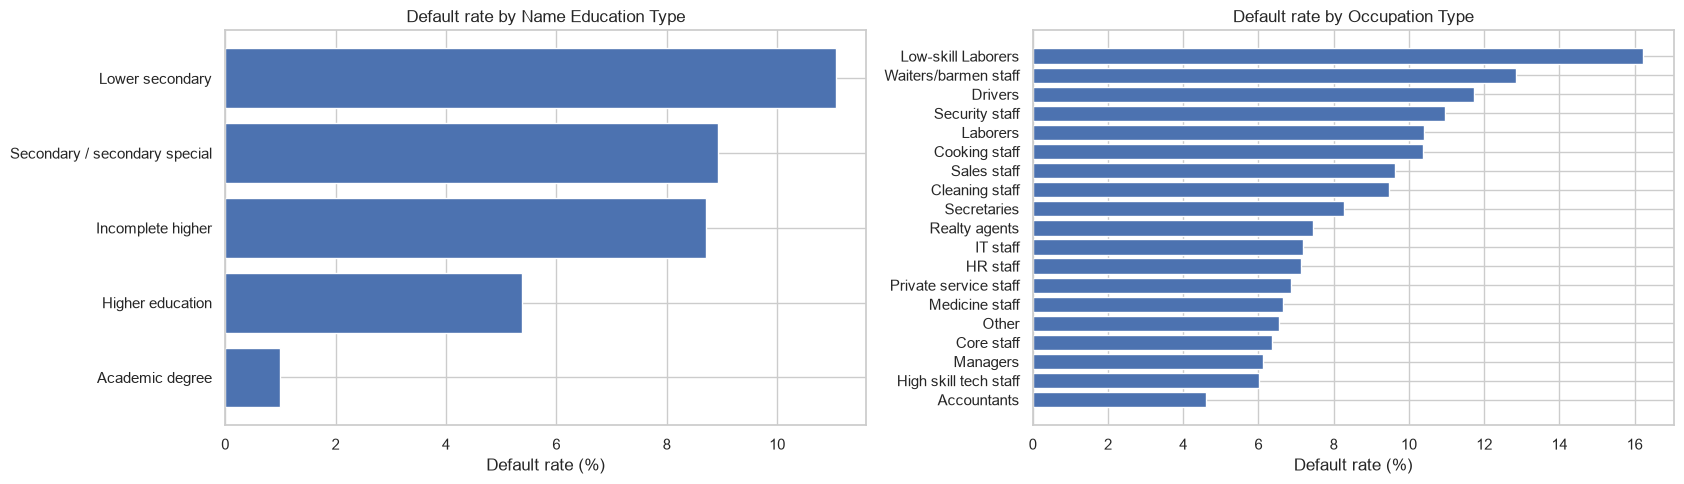

In [4]:
def default_rate_table(column, min_customers=100):
    table = (
        train.groupby(column, dropna=False)["TARGET"]
        .agg(["count", "mean"])
        .rename(columns={"count": "Customers", "mean": "Default rate"})
    )
    table["Default rate"] *= 100
    table = table[table["Customers"] >= min_customers]
    return table.sort_values("Default rate", ascending=False)

for column in ["NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "NAME_INCOME_TYPE"]:
    print("\n" + "=" * 70)
    print(column)
    display(default_rate_table(column).round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, column in zip(axes, ["NAME_EDUCATION_TYPE", "OCCUPATION_TYPE"]):
    table = default_rate_table(column)
    ax.barh(table.index, table["Default rate"], color="#4c72b0")
    ax.set_title(f"Default rate by {column.replace('_', ' ').title()}")
    ax.set_xlabel("Default rate (%)")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()


In [5]:
days_special = train["DAYS_EMPLOYED"] == 365243
org_xna = train["ORGANIZATION_TYPE"] == "XNA"

print("DAYS_EMPLOYED = 365243:", int(days_special.sum()), "rows")
print("Matches ORGANIZATION_TYPE = XNA exactly:", bool((days_special == org_xna).all()))
print("\nDefault rate by employment anomaly:")
display(train.groupby(days_special)["TARGET"].agg(["count", "mean"]).rename(
    index={False: "Normal", True: "365243 / XNA"}
).round(6))

numeric_columns = train.select_dtypes(include=[np.number]).columns.drop(["SK_ID_CURR", "TARGET"])
univariate = []
for column in numeric_columns:
    values = train[column]
    if values.nunique() < 2:
        continue
    auc = roc_auc_score(train["TARGET"], values.fillna(values.median()))
    univariate.append({"Feature": column, "Univariate AUC": auc, "Distance from 0.5": abs(auc - 0.5)})

univariate = pd.DataFrame(univariate).sort_values("Distance from 0.5", ascending=False)
print("\nStrongest univariate numeric signals (AUC can be below 0.5 when the relationship is inverse):")
display(univariate.head(15).drop(columns="Distance from 0.5").round(4))


DAYS_EMPLOYED = 365243: 30898 rows
Matches ORGANIZATION_TYPE = XNA exactly: True

Default rate by employment anomaly:


,count,mean
DAYS_EMPLOYED,,
Normal,140304,0.086562
365243 / XNA,30898,0.054243



Strongest univariate numeric signals (AUC can be below 0.5 when the relationship is inverse):


,Feature,Univariate AUC
17,EXT_SOURCE_2,0.3420
18,EXT_SOURCE_3,0.3687
6,DAYS_BIRTH,0.5844
16,EXT_SOURCE_1,0.4399
9,DAYS_ID_PUBLISH,0.5568
19,DAYS_LAST_PHONE_CHANGE,0.5565
15,REGION_RATING_CLIENT,0.5481
8,DAYS_REGISTRATION,0.5426
4,AMT_GOODS_PRICE,0.4641
5,REGION_POPULATION_RELATIVE,0.4650


In [6]:
# Adversarial validation: can a model distinguish train from test?
# An AUC close to 0.5 indicates that the random split is representative.
cat_columns = [
    "NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE", "ORGANIZATION_TYPE",
]

X_adv = train.drop(columns=["TARGET", "SK_ID_CURR"]).copy()
X_test_adv = test.drop(columns=["SK_ID_CURR"]).copy()

for column in cat_columns:
    categories = sorted(set(X_adv[column].astype(str)) | set(X_test_adv[column].astype(str)))
    dtype = pd.CategoricalDtype(categories=categories)
    X_adv[column] = X_adv[column].astype(str).astype(dtype)
    X_test_adv[column] = X_test_adv[column].astype(str).astype(dtype)

adversarial = pd.concat([X_adv, X_test_adv], axis=0, ignore_index=True)
adversarial_target = np.r_[np.zeros(len(X_adv)), np.ones(len(X_test_adv))]

adversarial_scores = []
for train_idx, valid_idx in StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE).split(
    adversarial, adversarial_target
):
    model = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=6,
        verbosity=-1,
    )
    model.fit(adversarial.iloc[train_idx], adversarial_target[train_idx])
    pred = model.predict_proba(adversarial.iloc[valid_idx])[:, 1]
    adversarial_scores.append(roc_auc_score(adversarial_target[valid_idx], pred))

print("Adversarial validation AUC per fold:", np.round(adversarial_scores, 4))
print("Mean adversarial AUC: {:.4f}".format(np.mean(adversarial_scores)))
print("Interpretation: values close to 0.5 mean train and test are hard to distinguish.")


Adversarial validation AUC per fold: [0.5139 0.5095 0.5161]
Mean adversarial AUC: 0.5131
Interpretation: values close to 0.5 mean train and test are hard to distinguish.


### EDA takeaways

- The target is imbalanced: **8.07%** of customers defaulted.
- The highest missing-value rates are in `EXT_SOURCE_1` (**69.47%**), `OWN_CAR_AGE` (**66.00%**), and `EXT_SOURCE_3` (**31.88%**).
- The special value `DAYS_EMPLOYED = 365243` is exactly equivalent to `ORGANIZATION_TYPE = "XNA"` (**30,898 rows, 18.05%**) and has a lower default rate (**5.42%** vs. **8.66%**).
- The strongest univariate numeric signals are `EXT_SOURCE_2`, `EXT_SOURCE_3`, `DAYS_BIRTH`, `EXT_SOURCE_1`, and recency variables such as `DAYS_ID_PUBLISH` and `DAYS_LAST_PHONE_CHANGE`.
- Adversarial validation is close to **0.51**, so the train/test split is broadly representative. Cross-validation should be a reasonable guide to test performance.


## 3. Feature engineering

All transformations are either row-wise or use only the feature distribution of train and test (frequency encoding). No target encoding is used, so there is no target leakage in this section.

The engineered feature groups are:

- **Employment anomaly:** flag for `DAYS_EMPLOYED = 365243`, then set the raw value to missing.
- **Time features:** age, years employed, years since registration, years since ID publication, and years since the last phone change.
- **Affordability ratios:** credit/income, annuity/income, credit/annuity, goods/income, credit/goods, credit term, income per family member, and related ratios.
- **Temporal ratios:** employment/age, registration/age, ID/age, phone change/age, and date differences.
- **`EXT_SOURCE` aggregates:** mean, standard deviation, minimum, maximum, product, missing count, and pairwise products.
- **Bureau-request summaries:** sum, maximum, mean, number of zeros, and a missing-all indicator.
- **Data-quality indicators:** missing flags for the main variables with missing values.
- **Frequency encoding:** category frequencies for `ORGANIZATION_TYPE` and `OCCUPATION_TYPE`, computed on train + test without the target.


In [7]:
def build_features(df):
    """Create model features from the raw application table.

    The function is applied identically to train and test. It uses no target
    information, so it can be safely used inside cross-validation.
    """
    df = df.copy()

    for column in cat_columns:
        df[column] = df[column].fillna("__MISSING__").astype(str)

    # Employment anomaly
    df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype("int8")
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

    # Time features
    df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
    df["EMPLOYED_YEARS"] = -df["DAYS_EMPLOYED"] / 365.25
    df["REGISTRATION_YEARS"] = -df["DAYS_REGISTRATION"] / 365.25
    df["ID_PUBLISH_YEARS"] = -df["DAYS_ID_PUBLISH"] / 365.25
    df["PHONE_CHANGE_YEARS"] = -df["DAYS_LAST_PHONE_CHANGE"] / 365.25

    # Affordability and credit ratios
    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    df["CREDIT_ANNUITY_RATIO"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"].replace(0, np.nan)
    df["GOODS_INCOME_RATIO"] = df["AMT_GOODS_PRICE"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    df["CREDIT_GOODS_RATIO"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"].replace(0, np.nan)
    df["CREDIT_GOODS_DIFF"] = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]
    df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"].replace(0, np.nan)
    df["ANNUITY_GOODS_RATIO"] = df["AMT_ANNUITY"] / df["AMT_GOODS_PRICE"].replace(0, np.nan)
    df["INCOME_PER_FAMILY"] = df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"].replace(0, np.nan)
    df["INCOME_PER_CHILD"] = df["AMT_INCOME_TOTAL"] / (df["CNT_CHILDREN"] + 1)
    df["CHILDREN_RATIO"] = df["CNT_CHILDREN"] / df["CNT_FAM_MEMBERS"].replace(0, np.nan)

    # Temporal ratios and differences
    df["EMPLOYED_AGE_RATIO"] = df["EMPLOYED_YEARS"] / df["AGE_YEARS"].replace(0, np.nan)
    df["REGISTRATION_AGE_RATIO"] = df["REGISTRATION_YEARS"] / df["AGE_YEARS"].replace(0, np.nan)
    df["ID_AGE_RATIO"] = df["ID_PUBLISH_YEARS"] / df["AGE_YEARS"].replace(0, np.nan)
    df["PHONE_AGE_RATIO"] = df["PHONE_CHANGE_YEARS"] / df["AGE_YEARS"].replace(0, np.nan)
    df["OWN_CAR_AGE_RATIO"] = df["OWN_CAR_AGE"] / df["AGE_YEARS"].replace(0, np.nan)
    df["AGE_EMPLOYED_DIFF"] = df["AGE_YEARS"] - df["EMPLOYED_YEARS"]
    df["REGISTRATION_ID_DIFF"] = df["DAYS_REGISTRATION"] - df["DAYS_ID_PUBLISH"]
    df["PHONE_REGISTRATION_DIFF"] = df["DAYS_LAST_PHONE_CHANGE"] - df["DAYS_REGISTRATION"]
    df["PHONE_CHANGE_ZERO"] = (df["DAYS_LAST_PHONE_CHANGE"] == 0).astype("int8")

    # EXT_SOURCE aggregates
    ext_columns = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df["EXT_SOURCE_MEAN"] = df[ext_columns].mean(axis=1)
    df["EXT_SOURCE_STD"] = df[ext_columns].std(axis=1)
    df["EXT_SOURCE_MIN"] = df[ext_columns].min(axis=1)
    df["EXT_SOURCE_MAX"] = df[ext_columns].max(axis=1)
    df["EXT_SOURCE_PROD"] = df[ext_columns].prod(axis=1, min_count=1)
    df["EXT_SOURCE_MISSING"] = df[ext_columns].isna().sum(axis=1)
    df["EXT_SOURCE_2_3"] = df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
    df["EXT_SOURCE_1_3"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_3"]
    df["EXT_SOURCE_1_2"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"]

    # Bureau-request summaries
    request_columns = [
        "AMT_REQ_CREDIT_BUREAU_HOUR",
        "AMT_REQ_CREDIT_BUREAU_MON",
        "AMT_REQ_CREDIT_BUREAU_QRT",
        "AMT_REQ_CREDIT_BUREAU_YEAR",
    ]
    df["BUREAU_REQ_SUM"] = df[request_columns].sum(axis=1, min_count=1)
    df["BUREAU_REQ_MAX"] = df[request_columns].max(axis=1)
    df["BUREAU_REQ_MEAN"] = df[request_columns].mean(axis=1)
    df["BUREAU_REQ_ZERO"] = (df[request_columns].fillna(0) == 0).sum(axis=1)
    df["BUREAU_REQ_NAN"] = df[request_columns].isna().all(axis=1).astype("int8")

    # Flag summary
    flags = ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE"]
    df["FLAG_SUM"] = df[flags].sum(axis=1)

    # Missing-value indicators
    for column in ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "DAYS_LAST_PHONE_CHANGE"]:
        df[f"{column}_MISSING"] = df[column].isna().astype("int8")

    # Log amounts (monotone, useful for linear components and stable scaling)
    for column in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
        df[f"LOG_{column}"] = np.log1p(df[column])

    # Ordinal education
    education_map = {
        "Lower secondary": 1,
        "Secondary / secondary special": 2,
        "Incomplete higher": 3,
        "Higher education": 4,
        "Academic degree": 5,
    }
    df["EDUCATION_ORDINAL"] = df["NAME_EDUCATION_TYPE"].map(education_map).fillna(0)

    return df


X = build_features(train.drop(columns=["TARGET", "SK_ID_CURR"]))
y = train["TARGET"].copy()
X_test = build_features(test.drop(columns=["SK_ID_CURR"]))

# Frequency encoding computed on train + test, without using the target.
combined = pd.concat([X, X_test], axis=0, ignore_index=True)
for column in ["ORGANIZATION_TYPE", "OCCUPATION_TYPE"]:
    frequency = combined[column].value_counts(normalize=True)
    X[f"{column}_FREQ"] = X[column].map(frequency)
    X_test[f"{column}_FREQ"] = X_test[column].map(frequency)

# Align categorical categories between train and test.
for column in cat_columns:
    categories = sorted(set(X[column].astype(str)) | set(X_test[column].astype(str)))
    dtype = pd.CategoricalDtype(categories=categories)
    X[column] = X[column].astype(str).astype(dtype)
    X_test[column] = X_test[column].astype(str).astype(dtype)

# CatBoost receives strings; LightGBM and XGBoost receive category dtype.
X_cat = X.copy()
X_test_cat = X_test.copy()
for column in cat_columns:
    X_cat[column] = X_cat[column].astype(str)
    X_test_cat[column] = X_test_cat[column].astype(str)

print("X shape:      ", X.shape)
print("X_test shape: ", X_test.shape)
print("Features:     ", X.shape[1])
print("Categorical:  ", len(cat_columns))
print("Numeric:      ", X.shape[1] - len(cat_columns))
print("\nNew feature names (last 25):")
print(list(X.columns[32:]))


X shape:       (171202, 84)
X_test shape:  (61500, 84)
Features:      84
Categorical:   8
Numeric:       76

New feature names (last 25):
['DAYS_EMPLOYED_ANOM', 'AGE_YEARS', 'EMPLOYED_YEARS', 'REGISTRATION_YEARS', 'ID_PUBLISH_YEARS', 'PHONE_CHANGE_YEARS', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'CREDIT_ANNUITY_RATIO', 'GOODS_INCOME_RATIO', 'CREDIT_GOODS_RATIO', 'CREDIT_GOODS_DIFF', 'CREDIT_TERM', 'ANNUITY_GOODS_RATIO', 'INCOME_PER_FAMILY', 'INCOME_PER_CHILD', 'CHILDREN_RATIO', 'EMPLOYED_AGE_RATIO', 'REGISTRATION_AGE_RATIO', 'ID_AGE_RATIO', 'PHONE_AGE_RATIO', 'OWN_CAR_AGE_RATIO', 'AGE_EMPLOYED_DIFF', 'REGISTRATION_ID_DIFF', 'PHONE_REGISTRATION_DIFF', 'PHONE_CHANGE_ZERO', 'EXT_SOURCE_MEAN', 'EXT_SOURCE_STD', 'EXT_SOURCE_MIN', 'EXT_SOURCE_MAX', 'EXT_SOURCE_PROD', 'EXT_SOURCE_MISSING', 'EXT_SOURCE_2_3', 'EXT_SOURCE_1_3', 'EXT_SOURCE_1_2', 'BUREAU_REQ_SUM', 'BUREAU_REQ_MAX', 'BUREAU_REQ_MEAN', 'BUREAU_REQ_ZERO', 'BUREAU_REQ_NAN', 'FLAG_SUM', 'EXT_SOURCE_1_MISSING', 'EXT_SOURCE_3_MISS

In [8]:
engineered_missing = X.isna().mean().sort_values(ascending=False).head(12)
print("Highest missing rates after feature engineering:")
display((engineered_missing * 100).round(2).to_frame("Missing (%)"))

print("Feature matrix preview:")
display(X.head())


Highest missing rates after feature engineering:


,Missing (%)
EXT_SOURCE_1_3,78.84
EXT_SOURCE_1_2,69.52
EXT_SOURCE_1,69.47
OWN_CAR_AGE,66.00
OWN_CAR_AGE_RATIO,66.00
EXT_SOURCE_2_3,32.01
EXT_SOURCE_3,31.88
EXT_SOURCE_STD,22.62
EMPLOYED_YEARS,18.05
DAYS_EMPLOYED,18.05


Feature matrix preview:


,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_ANOM,AGE_YEARS,EMPLOYED_YEARS,REGISTRATION_YEARS,ID_PUBLISH_YEARS,PHONE_CHANGE_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_ANNUITY_RATIO,GOODS_INCOME_RATIO,CREDIT_GOODS_RATIO,CREDIT_GOODS_DIFF,CREDIT_TERM,ANNUITY_GOODS_RATIO,INCOME_PER_FAMILY,INCOME_PER_CHILD,CHILDREN_RATIO,EMPLOYED_AGE_RATIO,REGISTRATION_AGE_RATIO,ID_AGE_RATIO,PHONE_AGE_RATIO,OWN_CAR_AGE_RATIO,AGE_EMPLOYED_DIFF,REGISTRATION_ID_DIFF,PHONE_REGISTRATION_DIFF,PHONE_CHANGE_ZERO,EXT_SOURCE_MEAN,EXT_SOURCE_STD,EXT_SOURCE_MIN,EXT_SOURCE_MAX,EXT_SOURCE_PROD,EXT_SOURCE_MISSING,EXT_SOURCE_2_3,EXT_SOURCE_1_3,EXT_SOURCE_1_2,BUREAU_REQ_SUM,BUREAU_REQ_MAX,BUREAU_REQ_MEAN,BUREAU_REQ_ZERO,BUREAU_REQ_NAN,FLAG_SUM,EXT_SOURCE_1_MISSING,EXT_SOURCE_3_MISSING,OWN_CAR_AGE_MISSING,DAYS_LAST_PHONE_CHANGE_MISSING,LOG_AMT_INCOME_TOTAL,LOG_AMT_CREDIT,LOG_AMT_ANNUITY,LOG_AMT_GOODS_PRICE,EDUCATION_ORDINAL,ORGANIZATION_TYPE_FREQ,OCCUPATION_TYPE_FREQ
0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,0.010032,-9233,-878.0,-333.0,-522,NaN,1,1,1,Core staff,2.0,2,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0,25.278576,2.403833,0.911704,1.429158,0.799452,6.712800,0.322920,20.787811,6.000000,1.118800,80190.0,0.048105,0.053820,56250.0,112500.0,0.0,0.095094,0.036066,0.056536,0.031626,NaN,22.874743,189.0,41.0,0,0.372591,NaN,0.372591,0.372591,0.372591,2,NaN,NaN,NaN,NaN,NaN,NaN,4,1,3,1,1,1,0,11.630717,13.534726,10.500385,13.422469,4,0.028900,0.088989
1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,0.008019,-20148,NaN,-4469.0,-3436,NaN,1,0,0,Other,2.0,2,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,1,55.162218,NaN,12.235455,9.407255,1.689254,2.600000,0.075080,34.629728,2.600000,1.000000,0.0,0.028877,0.028877,112500.0,225000.0,0.0,NaN,0.221809,0.170538,0.030623,NaN,NaN,-1033.0,3852.0,0,0.501366,0.073255,0.449567,0.553165,0.248685,1,0.248685,NaN,NaN,1.0,1.0,0.25,3,0,1,1,0,1,0,12.323860,13.279369,9.734714,13.279369,2,0.178181,0.311467
2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,0.004960,-18496,-523.0,-3640.0,-2050,NaN,1,1,1,Core staff,2.0,2,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0,50.639288,1.431896,9.965777,5.612594,1.483915,6.188000,0.338083,18.303180,5.000000,1.237600,64152.0,0.054635,0.067617,27000.0,54000.0,0.0,0.028276,0.196799,0.110835,0.029304,NaN,49.207392,-1590.0,3098.0,0,0.569503,NaN,0.569503,0.569503,0.569503,2,NaN,NaN,NaN,NaN,NaN,NaN,4,1,3,1,1,1,0,10.896758,12.719354,9.812331,12.506181,2,0.006919,0.088989
3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,0.005002,-24177,NaN,-4950.0,-3951,NaN,1,0,0,Other,1.0,3,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,1,66.193018,NaN,13.552361,10.817248,-0.000000,2.264000,0.131867,17.168857,2.000000,1.132000,17820.0,0.058245,0.065933,67500.0,67500.0,0.0,NaN,0.204740,0.163420,-0.000000,NaN,NaN,-999.0,4950.0,1,0.436379,0.468309,0.105235,0.767523,0.080770,1,0.080770,NaN,NaN,0.0,0.0,0.00,4,0,1,1,0,1,0,11.119898,11.937023,9.094031,11.813037,1,0.178181,0.311467
4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,0.006296,-10685,-697.0,-5101.0,-3226,NaN,1,1,1,Drivers,2.0,3,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,0,29.253936,1.908282,1

## 4. Validation protocol

The original notebook used the same validation fold for early stopping and for the OOF score. That makes the OOF estimate mildly optimistic. This notebook separates the two steps:

1. **Outer loop:** five stratified folds. The union of the five validation predictions forms the OOF vector used for evaluation.
2. **Inner split:** inside each outer training set, 15% of the rows are held out for early stopping. The outer validation fold is never touched during training.
3. **Final models:** after cross-validation, each algorithm is refitted on all training rows using the median number of trees found in the outer folds.

This protocol is more conservative than the original one. It gives a fairer estimate of how the model will behave on unseen customers.


In [9]:
folds = list(
    StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(X, y)
)

fold_id = np.zeros(len(y), dtype=int)
for fold, (_, valid_idx) in enumerate(folds):
    fold_id[valid_idx] = fold

print("Fold sizes and positive rates:")
for fold, (train_idx, valid_idx) in enumerate(folds, 1):
    print(
        f"Fold {fold}: train={len(train_idx):,} | valid={len(valid_idx):,} | "
        f"positive rate={y.iloc[valid_idx].mean():.4f}"
    )


def bootstrap_auc_ci(y_true, pred, n_boot=300, seed=RANDOM_STATE):
    """Percentile bootstrap confidence interval for ROC AUC."""
    y_true = np.asarray(y_true)
    pred = np.asarray(pred)
    rng = np.random.default_rng(seed)
    values = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].min() == y_true[idx].max():
            continue
        values.append(roc_auc_score(y_true[idx], pred[idx]))
    return np.percentile(values, [2.5, 97.5])


def paired_bootstrap_diff(y_true, pred_a, pred_b, n_boot=300, seed=RANDOM_STATE):
    """Paired bootstrap for AUC(a) - AUC(b), including a two-sided p-value."""
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)
    rng = np.random.default_rng(seed)
    differences = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].min() == y_true[idx].max():
            continue
        differences.append(
            roc_auc_score(y_true[idx], pred_a[idx]) - roc_auc_score(y_true[idx], pred_b[idx])
        )
    differences = np.asarray(differences)
    p_value = 2 * min(np.mean(differences <= 0), np.mean(differences >= 0))
    p_value = min(1.0, max(p_value, 1 / (len(differences) + 1)))
    return differences.mean(), np.percentile(differences, [2.5, 97.5]), p_value


Fold sizes and positive rates:
Fold 1: train=136,961 | valid=34,241 | positive rate=0.0807
Fold 2: train=136,961 | valid=34,241 | positive rate=0.0808
Fold 3: train=136,962 | valid=34,240 | positive rate=0.0807
Fold 4: train=136,962 | valid=34,240 | positive rate=0.0807
Fold 5: train=136,962 | valid=34,240 | positive rate=0.0807


## 5. Base models

Three gradient-boosting implementations are trained on the same folds and the same engineered features:

- **CatBoost** with native categorical handling.
- **LightGBM** with native categorical handling.
- **XGBoost** with `enable_categorical=True`.

The parameters are deliberately moderate. The objective is a fair, reproducible comparison, not an exhaustive hyperparameter search.


In [10]:
params_cat = {
    "iterations": 1200,
    "learning_rate": 0.04,
    "depth": 6,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "l2_leaf_reg": 5,
    "random_seed": RANDOM_STATE,
    "verbose": False,
    "allow_writing_files": False,
    "thread_count": 6,
}

params_lgb = {
    "objective": "binary",
    "n_estimators": 1200,
    "learning_rate": 0.04,
    "num_leaves": 40,
    "max_depth": -1,
    "min_child_samples": 50,
    "colsample_bytree": 0.8,
    "subsample": 0.8,
    "subsample_freq": 1,
    "reg_lambda": 2.0,
    "random_state": RANDOM_STATE,
    "n_jobs": 6,
    "verbosity": -1,
}

params_xgb = {
    "n_estimators": 1200,
    "learning_rate": 0.04,
    "max_depth": 5,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "hist",
    "enable_categorical": True,
    "random_state": RANDOM_STATE,
    "n_jobs": 6,
    "early_stopping_rounds": 100,
}

print("CatBoost parameters:")
print(json.dumps(params_cat, indent=2))
print("\nLightGBM parameters:")
print(json.dumps(params_lgb, indent=2))
print("\nXGBoost parameters:")
print(json.dumps(params_xgb, indent=2))


CatBoost parameters:
{
  "iterations": 1200,
  "learning_rate": 0.04,
  "depth": 6,
  "loss_function": "Logloss",
  "eval_metric": "AUC",
  "l2_leaf_reg": 5,
  "random_seed": 42,
  "verbose": false,
  "allow_writing_files": false,
  "thread_count": 6
}

LightGBM parameters:
{
  "objective": "binary",
  "n_estimators": 1200,
  "learning_rate": 0.04,
  "num_leaves": 40,
  "max_depth": -1,
  "min_child_samples": 50,
  "colsample_bytree": 0.8,
  "subsample": 0.8,
  "subsample_freq": 1,
  "reg_lambda": 2.0,
  "random_state": 42,
  "n_jobs": 6,
  "verbosity": -1
}

XGBoost parameters:
{
  "n_estimators": 1200,
  "learning_rate": 0.04,
  "max_depth": 5,
  "min_child_weight": 5,
  "subsample": 0.8,
  "colsample_bytree": 0.8,
  "reg_lambda": 5,
  "objective": "binary:logistic",
  "eval_metric": "auc",
  "tree_method": "hist",
  "enable_categorical": true,
  "random_state": 42,
  "n_jobs": 6,
  "early_stopping_rounds": 100
}


In [11]:
cat_oof = np.zeros(len(y))
cat_test_fold = np.zeros(len(X_test))
cat_scores = []
cat_iterations = []

for fold, (train_idx, valid_idx) in enumerate(folds, 1):
    X_train, X_valid = X_cat.iloc[train_idx], X_cat.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    X_fit, X_es, y_fit, y_es = train_test_split(
        X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE + fold
    )

    model = CatBoostClassifier(**params_cat)
    model.fit(
        X_fit,
        y_fit,
        cat_features=cat_columns,
        eval_set=(X_es, y_es),
        early_stopping_rounds=100,
        verbose=False,
    )

    pred_valid = model.predict_proba(X_valid)[:, 1]
    cat_oof[valid_idx] = pred_valid
    cat_test_fold += model.predict_proba(X_test_cat)[:, 1] / N_SPLITS
    cat_scores.append(roc_auc_score(y_valid, pred_valid))
    cat_iterations.append(model.best_iteration_)

    print(
        f"CatBoost | fold {fold}/{N_SPLITS} | AUC {cat_scores[-1]:.6f} | "
        f"best_iteration {model.best_iteration_}"
    )

print("\nCatBoost OOF AUC: {:.6f}".format(roc_auc_score(y, cat_oof)))
print("CatBoost mean fold AUC: {:.6f} +/- {:.6f}".format(np.mean(cat_scores), np.std(cat_scores, ddof=1)))


CatBoost | fold 1/5 | AUC 0.755671 | best_iteration 1199
CatBoost | fold 2/5 | AUC 0.758898 | best_iteration 987
CatBoost | fold 3/5 | AUC 0.764491 | best_iteration 1148
CatBoost | fold 4/5 | AUC 0.756004 | best_iteration 1176
CatBoost | fold 5/5 | AUC 0.759747 | best_iteration 858

CatBoost OOF AUC: 0.758897
CatBoost mean fold AUC: 0.758962 +/- 0.003563


In [12]:
lgb_oof = np.zeros(len(y))
lgb_test_fold = np.zeros(len(X_test))
lgb_scores = []
lgb_iterations = []

for fold, (train_idx, valid_idx) in enumerate(folds, 1):
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    X_fit, X_es, y_fit, y_es = train_test_split(
        X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE + fold
    )

    model = LGBMClassifier(**params_lgb)
    model.fit(
        X_fit,
        y_fit,
        eval_set=[(X_es, y_es)],
        eval_metric="auc",
        callbacks=[early_stopping(100, verbose=False)],
        categorical_feature=cat_columns,
    )

    pred_valid = model.predict_proba(X_valid)[:, 1]
    lgb_oof[valid_idx] = pred_valid
    lgb_test_fold += model.predict_proba(X_test)[:, 1] / N_SPLITS
    lgb_scores.append(roc_auc_score(y_valid, pred_valid))
    lgb_iterations.append(model.best_iteration_)

    print(
        f"LightGBM | fold {fold}/{N_SPLITS} | AUC {lgb_scores[-1]:.6f} | "
        f"best_iteration {model.best_iteration_}"
    )

print("\nLightGBM OOF AUC: {:.6f}".format(roc_auc_score(y, lgb_oof)))
print("LightGBM mean fold AUC: {:.6f} +/- {:.6f}".format(np.mean(lgb_scores), np.std(lgb_scores, ddof=1)))


LightGBM | fold 1/5 | AUC 0.751781 | best_iteration 271
LightGBM | fold 2/5 | AUC 0.758265 | best_iteration 223
LightGBM | fold 3/5 | AUC 0.761574 | best_iteration 221
LightGBM | fold 4/5 | AUC 0.752518 | best_iteration 241
LightGBM | fold 5/5 | AUC 0.756832 | best_iteration 245

LightGBM OOF AUC: 0.756109
LightGBM mean fold AUC: 0.756194 +/- 0.004081


In [13]:
xgb_oof = np.zeros(len(y))
xgb_test_fold = np.zeros(len(X_test))
xgb_scores = []
xgb_iterations = []

for fold, (train_idx, valid_idx) in enumerate(folds, 1):
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    X_fit, X_es, y_fit, y_es = train_test_split(
        X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE + fold
    )

    model = XGBClassifier(**params_xgb)
    model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)

    pred_valid = model.predict_proba(X_valid)[:, 1]
    xgb_oof[valid_idx] = pred_valid
    xgb_test_fold += model.predict_proba(X_test)[:, 1] / N_SPLITS
    xgb_scores.append(roc_auc_score(y_valid, pred_valid))
    xgb_iterations.append(model.best_iteration)

    print(
        f"XGBoost | fold {fold}/{N_SPLITS} | AUC {xgb_scores[-1]:.6f} | "
        f"best_iteration {model.best_iteration}"
    )

print("\nXGBoost OOF AUC: {:.6f}".format(roc_auc_score(y, xgb_oof)))
print("XGBoost mean fold AUC: {:.6f} +/- {:.6f}".format(np.mean(xgb_scores), np.std(xgb_scores, ddof=1)))


XGBoost | fold 1/5 | AUC 0.751273 | best_iteration 543
XGBoost | fold 2/5 | AUC 0.756883 | best_iteration 353
XGBoost | fold 3/5 | AUC 0.760451 | best_iteration 437
XGBoost | fold 4/5 | AUC 0.750922 | best_iteration 341
XGBoost | fold 5/5 | AUC 0.754772 | best_iteration 572

XGBoost OOF AUC: 0.754773
XGBoost mean fold AUC: 0.754860 +/- 0.003992


In [14]:
model_rows = []
for model_name, scores, oof in [
    ("CatBoost", cat_scores, cat_oof),
    ("LightGBM", lgb_scores, lgb_oof),
    ("XGBoost", xgb_scores, xgb_oof),
]:
    ci_low, ci_high = bootstrap_auc_ci(y, oof)
    model_rows.append({
        "Model": model_name,
        "Mean fold AUC": np.mean(scores),
        "Fold SD": np.std(scores, ddof=1),
        "OOF AUC": roc_auc_score(y, oof),
        "95% CI low": ci_low,
        "95% CI high": ci_high,
    })

model_results = pd.DataFrame(model_rows).sort_values("OOF AUC", ascending=False)
print("Base-model results:")
display(model_results.round(6))

per_fold = pd.DataFrame({
    "Fold": range(1, N_SPLITS + 1),
    "CatBoost": cat_scores,
    "LightGBM": lgb_scores,
    "XGBoost": xgb_scores,
})
print("Per-fold AUC:")
display(per_fold.round(6))


Base-model results:


,Model,Mean fold AUC,Fold SD,OOF AUC,95% CI low,95% CI high
0,CatBoost,0.758962,0.003563,0.758897,0.754609,0.763104
1,LightGBM,0.756194,0.004081,0.756109,0.751459,0.760112
2,XGBoost,0.754860,0.003992,0.754773,0.750199,0.758642


Per-fold AUC:


,Fold,CatBoost,LightGBM,XGBoost
0,1,0.755671,0.751781,0.751273
1,2,0.758898,0.758265,0.756883
2,3,0.764491,0.761574,0.760451
3,4,0.756004,0.752518,0.750922
4,5,0.759747,0.756832,0.754772


## 6. Ensemble without optimistic weight selection

A common mistake is to choose ensemble weights on the same OOF predictions that are then used to report the ensemble score. That procedure is optimistically biased. This notebook uses **nested weight selection**:

- For each outer fold `k`, the weights are chosen using only the OOF rows from the other four folds.
- The chosen weights are applied to fold `k`, which was not used to choose them.
- The resulting nested OOF predictions are used to estimate the performance of the blending procedure.

The same logic is applied to a logistic-regression stack on logit-transformed OOF predictions. Simple average and rank average are included as parameter-free benchmarks.


In [15]:
P = np.column_stack([cat_oof, lgb_oof, xgb_oof])
y_array = np.asarray(y)


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def best_weight_blend(predictions, target, step=0.05):
    """Grid-search non-negative weights that sum to one."""
    best_auc = -np.inf
    best_weights = None
    for weight_cat in np.arange(0, 1 + 1e-9, step):
        for weight_lgb in np.arange(0, 1 - weight_cat + 1e-9, step):
            weight_xgb = 1 - weight_cat - weight_lgb
            weights = np.array([weight_cat, weight_lgb, weight_xgb])
            auc = roc_auc_score(target, predictions @ weights)
            if auc > best_auc:
                best_auc = auc
                best_weights = weights
    return best_weights, best_auc


# Nested weighted blend
nested_weight_oof = np.zeros(len(y))
nested_weights = []
for fold in range(N_SPLITS):
    train_mask = fold_id != fold
    valid_mask = fold_id == fold
    weights, _ = best_weight_blend(P[train_mask], y_array[train_mask])
    nested_weight_oof[valid_mask] = P[valid_mask] @ weights
    nested_weights.append(weights)

# Nested logistic stack
Z = logit(P)
nested_stack_oof = np.zeros(len(y))
for fold in range(N_SPLITS):
    train_mask = fold_id != fold
    valid_mask = fold_id == fold
    meta_model = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)
    meta_model.fit(Z[train_mask], y_array[train_mask])
    nested_stack_oof[valid_mask] = meta_model.predict_proba(Z[valid_mask])[:, 1]

# Parameter-free benchmarks
average_oof = P.mean(axis=1)
rank_oof = np.mean([rankdata(P[:, j]) / len(P) for j in range(P.shape[1])], axis=0)

# In-sample weights, shown only to quantify the optimistic bias.
in_sample_weights, in_sample_auc = best_weight_blend(P, y_array)
in_sample_oof = P @ in_sample_weights

print("Nested weights by fold (CatBoost, LightGBM, XGBoost):")
for fold, weights in enumerate(nested_weights, 1):
    print(f"  Fold {fold}: {np.round(weights, 3)}")
print("\nIn-sample weights (optimistic):", np.round(in_sample_weights, 3))
print("In-sample weighted OOF AUC: {:.6f}".format(in_sample_auc))


Nested weights by fold (CatBoost, LightGBM, XGBoost):
  Fold 1: [0.6 0.3 0.1]
  Fold 2: [0.65 0.2  0.15]
  Fold 3: [0.65 0.25 0.1 ]
  Fold 4: [0.6  0.25 0.15]
  Fold 5: [0.65 0.25 0.1 ]

In-sample weights (optimistic): [0.65 0.25 0.1 ]
In-sample weighted OOF AUC: 0.759980


In [16]:
ensemble_candidates = {
    "CatBoost": cat_oof,
    "LightGBM": lgb_oof,
    "XGBoost": xgb_oof,
    "Simple average": average_oof,
    "Rank average": rank_oof,
    "Nested weighted blend": nested_weight_oof,
    "Nested logistic stack": nested_stack_oof,
}

ensemble_rows = []
for name, prediction in ensemble_candidates.items():
    ci_low, ci_high = bootstrap_auc_ci(y, prediction)
    fold_scores = [
        roc_auc_score(y_array[fold_id == fold], prediction[fold_id == fold])
        for fold in range(N_SPLITS)
    ]
    ensemble_rows.append({
        "Strategy": name,
        "Mean fold AUC": np.mean(fold_scores),
        "Fold SD": np.std(fold_scores, ddof=1),
        "OOF AUC": roc_auc_score(y_array, prediction),
        "95% CI low": ci_low,
        "95% CI high": ci_high,
    })

ensemble_results = pd.DataFrame(ensemble_rows).sort_values("OOF AUC", ascending=False)
print("Ensemble comparison (nested strategies are the honest estimates):")
display(ensemble_results.round(6))

print("\nFor reference, the in-sample weighted blend would report:")
print("  OOF AUC = {:.6f} (optimistic; weights were fitted on these same rows)".format(in_sample_auc))


Ensemble comparison (nested strategies are the honest estimates):


,Strategy,Mean fold AUC,Fold SD,OOF AUC,95% CI low,95% CI high
5,Nested weighted blend,0.760009,0.003760,0.759940,0.755508,0.764111
6,Nested logistic stack,0.759935,0.003781,0.759832,0.755353,0.763978
3,Simple average,0.759310,0.003909,0.759240,0.754645,0.763369
4,Rank average,0.759242,0.003823,0.759168,0.754592,0.763277
0,CatBoost,0.758962,0.003563,0.758897,0.754609,0.763104
1,LightGBM,0.756194,0.004081,0.756109,0.751459,0.760112
2,XGBoost,0.754860,0.003992,0.754773,0.750199,0.758642



For reference, the in-sample weighted blend would report:
  OOF AUC = 0.759980 (optimistic; weights were fitted on these same rows)


In [17]:
best_strategy = ensemble_results.iloc[0]["Strategy"]
best_oof = ensemble_candidates[best_strategy]

difference, difference_ci, p_value = paired_bootstrap_diff(y_array, best_oof, cat_oof)
fold_best = [
    roc_auc_score(y_array[fold_id == fold], best_oof[fold_id == fold])
    for fold in range(N_SPLITS)
]
fold_cat = [
    roc_auc_score(y_array[fold_id == fold], cat_oof[fold_id == fold])
    for fold in range(N_SPLITS)
]
t_stat, t_p_value = ttest_rel(fold_best, fold_cat)

print("Best strategy by nested OOF AUC:", best_strategy)
print("Best OOF AUC: {:.6f}".format(roc_auc_score(y_array, best_oof)))
print("CatBoost OOF AUC: {:.6f}".format(roc_auc_score(y_array, cat_oof)))
print("Paired difference (best - CatBoost): {:+.6f}".format(difference))
print("95% bootstrap CI: [{:+.6f}, {:+.6f}]".format(difference_ci[0], difference_ci[1]))
print("Bootstrap two-sided p-value: {:.4f}".format(p_value))
print("Fold-level paired t-test: t = {:.3f}, p = {:.4f}".format(t_stat, t_p_value))


Best strategy by nested OOF AUC: Nested weighted blend
Best OOF AUC: 0.759940
CatBoost OOF AUC: 0.758897
Paired difference (best - CatBoost): +0.001046
95% bootstrap CI: [+0.000572, +0.001466]
Bootstrap two-sided p-value: 0.0033
Fold-level paired t-test: t = 5.830, p = 0.0043


## 7. Final models and submission

The cross-validated models are useful for evaluation, but the final test predictions should use all available training rows. Each algorithm is therefore refitted on the full training set with the median number of trees found in the outer folds (multiplied by 1.1 to account for the larger training set).

The final blending rule is the strategy with the best **nested** OOF AUC. The rule is then fitted on all OOF rows and applied to the full-data test predictions.


In [18]:
n_cat_full = max(100, int(np.median(cat_iterations) * 1.1))
n_lgb_full = max(100, int(np.median(lgb_iterations) * 1.1))
n_xgb_full = max(100, int(np.median(xgb_iterations) * 1.1))

print("Full-model iterations:")
print("  CatBoost:", n_cat_full)
print("  LightGBM:", n_lgb_full)
print("  XGBoost: ", n_xgb_full)

full_start = time.time()

cat_full = CatBoostClassifier(**{**params_cat, "iterations": n_cat_full})
cat_full.fit(X_cat, y, cat_features=cat_columns, verbose=False)
cat_test_full = cat_full.predict_proba(X_test_cat)[:, 1]

lgb_full = LGBMClassifier(**{**params_lgb, "n_estimators": n_lgb_full})
lgb_full.fit(X, y)
lgb_test_full = lgb_full.predict_proba(X_test)[:, 1]

xgb_full_params = {key: value for key, value in params_xgb.items() if key != "early_stopping_rounds"}
xgb_full = XGBClassifier(**{**xgb_full_params, "n_estimators": n_xgb_full})
xgb_full.fit(X, y, verbose=False)
xgb_test_full = xgb_full.predict_proba(X_test)[:, 1]

print("Full models trained in {:.1f} seconds.".format(time.time() - full_start))
print("Test predictions:")
print("  CatBoost: mean {:.6f}, min {:.6f}, max {:.6f}".format(
    cat_test_full.mean(), cat_test_full.min(), cat_test_full.max()))
print("  LightGBM: mean {:.6f}, min {:.6f}, max {:.6f}".format(
    lgb_test_full.mean(), lgb_test_full.min(), lgb_test_full.max()))
print("  XGBoost:  mean {:.6f}, min {:.6f}, max {:.6f}".format(
    xgb_test_full.mean(), xgb_test_full.min(), xgb_test_full.max()))


Full-model iterations:
  CatBoost: 1262
  LightGBM: 265
  XGBoost:  480
Full models trained in 336.7 seconds.
Test predictions:
  CatBoost: mean 0.088558, min 0.001353, max 0.807836
  LightGBM: mean 0.088425, min 0.003830, max 0.735551
  XGBoost:  mean 0.088421, min 0.001705, max 0.769321


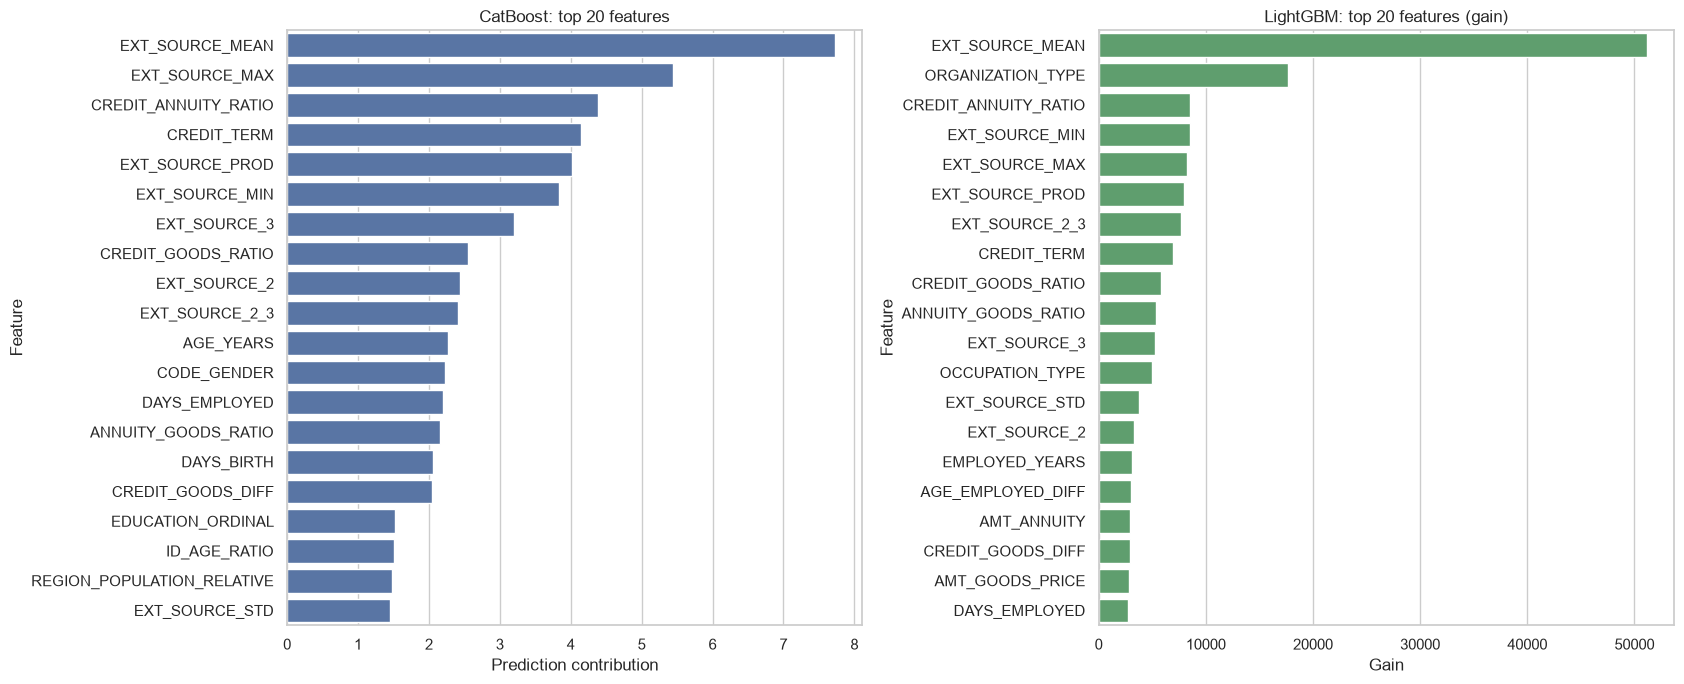

CatBoost top 20:


,Feature,Importance
0,EXT_SOURCE_MEAN,7.7270
1,EXT_SOURCE_MAX,5.4464
2,CREDIT_ANNUITY_RATIO,4.3874
3,CREDIT_TERM,4.1392
4,EXT_SOURCE_PROD,4.0161
5,EXT_SOURCE_MIN,3.8362
6,EXT_SOURCE_3,3.2043
7,CREDIT_GOODS_RATIO,2.5559
8,EXT_SOURCE_2,2.4355
9,EXT_SOURCE_2_3,2.4133


LightGBM top 20:


,Feature,Importance
58,EXT_SOURCE_MEAN,51131.3313
23,ORGANIZATION_TYPE,17692.7154
40,CREDIT_ANNUITY_RATIO,8491.1182
60,EXT_SOURCE_MIN,8480.1238
61,EXT_SOURCE_MAX,8198.6830
62,EXT_SOURCE_PROD,7947.9959
64,EXT_SOURCE_2_3,7696.8648
44,CREDIT_TERM,6974.7676
42,CREDIT_GOODS_RATIO,5829.9528
45,ANNUITY_GOODS_RATIO,5338.7304


In [19]:
cat_importance = cat_full.get_feature_importance(prettified=True)
cat_importance.columns = ["Feature", "Importance"]
cat_importance = cat_importance.sort_values("Importance", ascending=False).head(20)

lgb_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": lgb_full.booster_.feature_importance(importance_type="gain"),
}).sort_values("Importance", ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.barplot(data=cat_importance, x="Importance", y="Feature", ax=axes[0], color="#4c72b0")
axes[0].set_title("CatBoost: top 20 features")
axes[0].set_xlabel("Prediction contribution")

sns.barplot(data=lgb_importance, x="Importance", y="Feature", ax=axes[1], color="#55a868")
axes[1].set_title("LightGBM: top 20 features (gain)")
axes[1].set_xlabel("Gain")

plt.tight_layout()
plt.show()

print("CatBoost top 20:")
display(cat_importance.round(4))
print("LightGBM top 20:")
display(lgb_importance.round(4))


In [20]:
P_test = np.column_stack([cat_test_full, lgb_test_full, xgb_test_full])

# Refit the chosen blending rule on all OOF rows and apply it to test predictions.
if best_strategy == "CatBoost":
    final_test = cat_test_full
    blend_description = "CatBoost only"
elif best_strategy == "LightGBM":
    final_test = lgb_test_full
    blend_description = "LightGBM only"
elif best_strategy == "XGBoost":
    final_test = xgb_test_full
    blend_description = "XGBoost only"
elif best_strategy == "Simple average":
    final_test = P_test.mean(axis=1)
    blend_description = "Equal-weight average of CatBoost, LightGBM, and XGBoost"
elif best_strategy == "Rank average":
    final_test = np.mean(
        [rankdata(P_test[:, j]) / len(P_test) for j in range(P_test.shape[1])], axis=0
    )
    blend_description = "Rank average of CatBoost, LightGBM, and XGBoost"
elif best_strategy == "Nested weighted blend":
    final_weights, _ = best_weight_blend(P, y_array)
    final_test = P_test @ final_weights
    blend_description = "Weighted blend with weights {}".format(np.round(final_weights, 3))
elif best_strategy == "Nested logistic stack":
    meta_full = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)
    meta_full.fit(Z, y_array)
    final_test = meta_full.predict_proba(logit(P_test))[:, 1]
    blend_description = "Logistic stack with coefficients {}".format(
        np.round(meta_full.coef_[0], 3)
    )
else:
    raise ValueError(f"Unknown strategy: {best_strategy}")

final_test = np.clip(np.asarray(final_test), 0.0, 1.0)
print("Final strategy:", best_strategy)
print("Description:   ", blend_description)
print("Final test prediction summary:")
print(pd.Series(final_test).describe().round(6))


Final strategy: Nested weighted blend
Description:    Weighted blend with weights [0.65 0.25 0.1 ]
Final test prediction summary:
count    61500.000000
mean         0.088511
std          0.088161
min          0.002461
25%          0.030348
50%          0.058280
75%          0.113116
max          0.773926
dtype: float64


In [21]:
submission = pd.DataFrame({
    "SK_ID_CURR": test["SK_ID_CURR"].values,
    "TARGET": final_test,
})

assert len(submission) == len(test) == 61500, "Submission must have 61,500 rows."
assert submission["SK_ID_CURR"].is_unique, "SK_ID_CURR must be unique."
assert (submission["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all(), "ID order mismatch."
assert submission["TARGET"].notna().all(), "Submission contains missing values."
assert submission["TARGET"].between(0, 1).all(), "Probabilities must be in [0, 1]."

submission.to_csv("submission.csv", index=False)

oof_export = pd.DataFrame({
    "SK_ID_CURR": train["SK_ID_CURR"].values,
    "TARGET": y.values,
    "CATBOOST": cat_oof,
    "LIGHTGBM": lgb_oof,
    "XGBOOST": xgb_oof,
    "BEST_ENSEMBLE": best_oof,
})
oof_export.to_csv("oof_predictions.csv", index=False)

test_export = pd.DataFrame({
    "SK_ID_CURR": test["SK_ID_CURR"].values,
    "CATBOOST": cat_test_full,
    "LIGHTGBM": lgb_test_full,
    "XGBOOST": xgb_test_full,
    "FINAL": final_test,
})
test_export.to_csv("test_predictions.csv", index=False)

print("Saved submission.csv, oof_predictions.csv, and test_predictions.csv.")
print("Submission shape:", submission.shape)
display(submission.head(10))
display(submission["TARGET"].describe().to_frame().T.round(6))


Saved submission.csv, oof_predictions.csv, and test_predictions.csv.
Submission shape: (61500, 2)


,SK_ID_CURR,TARGET
0,171202,0.028932
1,171203,0.174762
2,171204,0.144702
3,171205,0.120269
4,171206,0.196121
5,171207,0.023807
6,171208,0.169596
7,171209,0.046406
8,171210,0.117747
9,171211,0.130262


,count,mean,std,min,25%,50%,75%,max
TARGET,61500.0,0.088511,0.088161,0.002461,0.030348,0.05828,0.113116,0.773926


## 8. Conclusions

<!-- RESULTS_PLACEHOLDER -->

### Limitations

- All reported scores are out-of-fold estimates on the training data. The test labels are unavailable, so the leaderboard score can differ.
- The outer validation fold is not used for early stopping, but the inner split reduces the data available to each fold model. This makes the OOF estimate slightly conservative relative to a full-data model.
- The ensemble rule is selected on the nested OOF results. This is much safer than tuning on the final OOF score, but it is still a model-selection step on the same dataset.
- Hyperparameters were fixed at moderate values. A nested hyperparameter search could improve the score further, at a substantial computational cost.
- The competition forbids external data, so the model uses only `train.csv` and `test.csv`.

### Recommended next steps

1. Run a nested Optuna search for CatBoost and LightGBM, keeping hyperparameter selection inside each outer fold.
2. Add seed averaging: train each model with three seeds and average the test predictions.
3. Test a small set of additional feature groups, such as category target encoding fitted inside each fold and interaction terms between `EXT_SOURCE` and affordability ratios.
4. Evaluate a wider set of blending rules, including constrained logistic stacking and rank-based blends.
5. Monitor the public leaderboard with a small number of submissions and keep the final submission consistent with the cross-validated choice.


## 9. Reproducibility

- **Random seed:** 42 for folds, models, and bootstrap resampling.
- **Validation:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
- **Environment:** Python 3.14.6, pandas 3.0.3, numpy 2.5.0, scikit-learn 1.9.1, LightGBM 4.7.0, CatBoost 1.2.10, XGBoost 3.4.1.
- **Outputs:** `submission.csv`, `oof_predictions.csv`, and `test_predictions.csv`.
- **Runtime:** the full notebook is designed to run on a 6-core CPU in roughly 30–45 minutes, depending on early-stopping behavior.

The notebook uses only `train.csv` and `test.csv`. No external data, hand-labeling, or target leakage is used.


In [22]:
elapsed_minutes = (time.time() - START_TIME) / 60
print("Notebook runtime: {:.1f} minutes".format(elapsed_minutes))
print("Files written:")
for filename in ["submission.csv", "oof_predictions.csv", "test_predictions.csv"]:
    path = Path(filename)
    print(f"  {filename}: exists={path.exists()}, size={path.stat().st_size if path.exists() else 0} bytes")


Notebook runtime: 38.1 minutes
Files written:
  submission.csv: exists=True, size=1728852 bytes
  oof_predictions.csv: exists=True, size=15399645 bytes
  test_predictions.csv: exists=True, size=4902943 bytes
